<a href="https://colab.research.google.com/github/annikagabhart/QuantumHackathon_2026/blob/main/QuantumHackathon_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Is This Element Metallic?

In [ ]:
# ---- Setup: installs anything missing (needed in Google Colab, harmless elsewhere) ----
import importlib.util, subprocess, sys
needed = {"qiskit": "qiskit", "qiskit_machine_learning": "qiskit-machine-learning",
          "pylatexenc": "pylatexenc", "sklearn": "scikit-learn", "pandas": "pandas"}
missing = [pip_name for mod, pip_name in needed.items() if importlib.util.find_spec(mod) is None]
IN_COLAB = "google.colab" in sys.modules
if missing and IN_COLAB:
    print("Installing:", *missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
elif missing:
    # On your own computer we do NOT install into your current environment: Qiskit needs NumPy 2,
    # which can break older packages (pandas, tensorflow, numba, ...) that were built for NumPy 1.
    raise SystemExit(
        "Missing packages: " + ", ".join(missing) + "\n\nPlease create a clean environment once, in a terminal:\n"
        "    python3 -m venv qml-env\n"
        "    source qml-env/bin/activate        (Windows: qml-env\\Scripts\\activate)\n"
        "    pip install -r requirements.txt\n"
        "    python -m ipykernel install --user --name qml-env --display-name \"QML (qiskit)\"\n"
        "then restart Jupyter and choose  Kernel -> Change kernel -> QML (qiskit).\n"
        "Or simply upload this notebook to Google Colab and use Runtime -> Run all.")

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from IPython.display import display

import qiskit, qiskit_machine_learning, sklearn
print(f"qiskit {qiskit.__version__} | qiskit-machine-learning {qiskit_machine_learning.__version__} | "
      f"scikit-learn {sklearn.__version__} | numpy {np.__version__}")

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

# One fixed colour per role, used everywhere in the notebook
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
CLASS_COLORS = [BLUE, ORANGE]                          # class 0, class 1
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f2f2f0", ORANGE])  # decision function
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f7f7f5", "#9cc3ee", BLUE, "#123d73"])  # kernel values

SEED = 42
rng = np.random.default_rng(SEED)

def show(fig):
    # display a figure returned by Qiskit (circuit drawings, histograms) exactly once
    display(fig); plt.close(fig)

qiskit 2.6.1 | qiskit-machine-learning 0.9.1 | scikit-learn 1.6.1 | numpy 2.1.3


<>:22: SyntaxWarning: invalid escape sequence '\c'
<>:22: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1685/1205291349.py:22: SyntaxWarning: invalid escape sequence '\c'
  plt.xlabel('Pauling Electronegativity $\chi$')


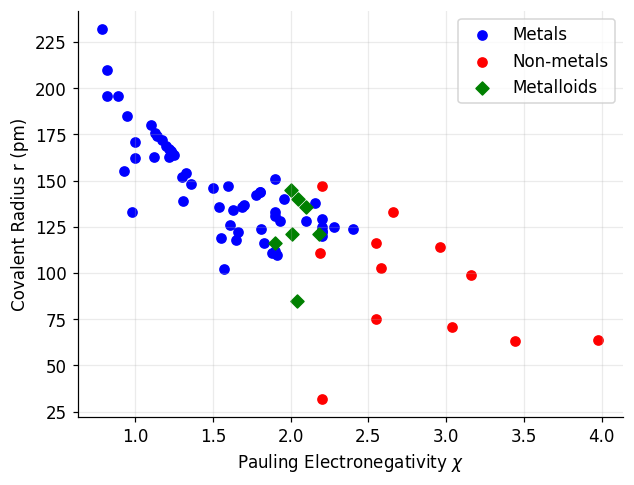

In [ ]:
from qiskit_machine_learning.utils import algorithm_globals

# The random seed fixes the hidden "labelling rule" (a random observable), so both calls use the same rule.
ad_hoc_data = "/content/sample_data/elements_dataset.csv"
radius_pm = pd.read_csv(ad_hoc_data, usecols=['covalent_radius_pm'])
electronegativity = pd.read_csv(ad_hoc_data, usecols=['electronegativity'])
radius = radius_pm['covalent_radius_pm'].values
eneg = electronegativity['electronegativity'].values
metal_type = pd.read_csv(ad_hoc_data, usecols=['class'])
metal_class = metal_type['class'].values

# Create masks to separate the classes
metals = metal_class == "metal"
nonmetals = metal_class == "non-metal"
metalloids = metal_class == "metalloid"

# Plot each class separately
plt.scatter(eneg[metals], radius[metals], color="blue", label="Metals")
plt.scatter(eneg[nonmetals], radius[nonmetals], color="red", label="Non-metals")
plt.scatter(eneg[metalloids], radius[metalloids], color="green", marker='D', label="Metalloids")
plt.ylabel('Covalent Radius r (pm)')
plt.xlabel('Pauling Electronegativity $\chi$')
plt.legend()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
df = pd.read_csv(ad_hoc_data)
training_data = df[['electronegativity','covalent_radius_pm']].to_numpy()
x_train, x_test, y_train, y_test = train_test_split(
    training_data,
    metal_class,
    train_size=10,
    test_size=10,
    random_state=52
    )
x_big, _, y_big, _ = train_test_split(
    training_data,
    metal_class,
    train_size=65,
    test_size=0.05
)

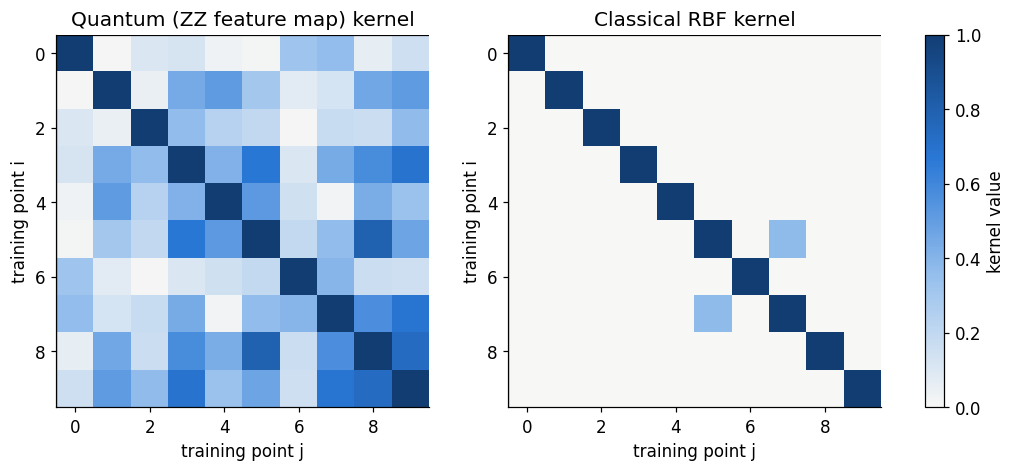

In [ ]:
fmap = zz_feature_map(feature_dimension=2, reps=2)
qkernel = FidelityStatevectorKernel(feature_map=fmap)

K_train_q = qkernel.evaluate(x_train)
K_test_q = qkernel.evaluate(x_test, x_train)

order = np.argsort(y_train, kind="stable")
n0 = (y_train == 0).sum()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, K, name in [(axes[0], K_train_q, "Quantum (ZZ feature map) kernel"),
                    (axes[1], rbf_kernel(x_train, gamma=1.0), "Classical RBF kernel")]:
    im = ax.imshow(K[np.ix_(order, order)], cmap=SEQUENTIAL, vmin=0, vmax=1)
    ax.axhline(n0 - 0.5, color="k", lw=0.8); ax.axvline(n0 - 0.5, color="k", lw=0.8)
    ax.set_title(name); ax.grid(False); ax.set_xlabel("training point j"); ax.set_ylabel("training point i")
plt.colorbar(im, ax=axes, fraction=0.025, label="kernel value")
plt.show()

In [ ]:
from qiskit_machine_learning.algorithms import QSVC
from sklearn.model_selection import GridSearchCV

# 1) by hand: classical SVM + quantum kernel matrix
svm_q = SVC(kernel="precomputed").fit(K_train_q, y_train)
acc_q = svm_q.score(K_test_q, y_test)

# 2) the same with QSVC
qsvc = QSVC(quantum_kernel=qkernel).fit(x_train, y_train)
acc_qsvc = qsvc.score(x_test, y_test)

# classical baseline, tuned
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10, "scale"]}, cv=5)
grid.fit(x_train, y_train)
acc_rbf = grid.score(x_test, y_test)

results_adhoc = pd.DataFrame({
    "model": ["SVC + quantum kernel (precomputed)", "QSVC (Qiskit ML)", f"classical RBF SVM, tuned {grid.best_params_}"],
    "test accuracy": [acc_q, acc_qsvc, acc_rbf]})
print("x_big shape:", x_big.shape)
print("y_big shape:", y_big.shape)
print("x_train shape:", x_train.shape)

print("Kernel matrix shape:",
      qkernel.evaluate(x_big, x_train).shape)
results_adhoc["accuracy on the 65 extra points"] = [
    svm_q.score(qkernel.evaluate(x_big, x_train), y_big), qsvc.score(x_big, y_big), grid.score(x_big, y_big)]
display(results_adhoc.style.format("{:.2f}", subset=["test accuracy", "accuracy on the 65 extra points"]).hide(axis="index"))
print(f"support vectors used by the quantum SVM: {len(svm_q.support_)} of {len(y_train)}")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


x_big shape: (65, 2)
y_big shape: (65,)
x_train shape: (10, 2)
Kernel matrix shape: (65, 10)


model,test accuracy,accuracy on the 65 extra points
SVC + quantum kernel (precomputed),0.90,0.74
QSVC (Qiskit ML),0.90,0.74
"classical RBF SVM, tuned {'C': 0.1, 'gamma': 0.01}",0.90,0.74


support vectors used by the quantum SVM: 9 of 10


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler import generate_preset_pass_manager

QiskitRuntimeService.save_account(
    token="5gHWvj5RMS8HbFK3Gl9t9W9sdkIXStAP9XavSfYjwOo5",
    instance="crn:v1:bluemix:public:quantum-computing:us-east:a/e3bd5ea8e18642889c47c9ab7357f66b:e8ce773d-51e1-408b-9634-91af34d06177::", # Optional
    overwrite = True
)

from qiskit_ibm_runtime import QiskitRuntimeService

# Run every time you need the service
service = QiskitRuntimeService()

# one-time: QiskitRuntimeService.save_account(token="YOUR_API_KEY", instance="YOUR_CRN", overwrite=True)
backend = service.least_busy(operational=True, simulator=False)
print("running on", backend.name)


running on ibm_kingston


In [ ]:
from qiskit.circuit.library import real_amplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA

ansatz = real_amplitudes(num_qubits=2, reps=3)

training took 12 s and 66 loss evaluations


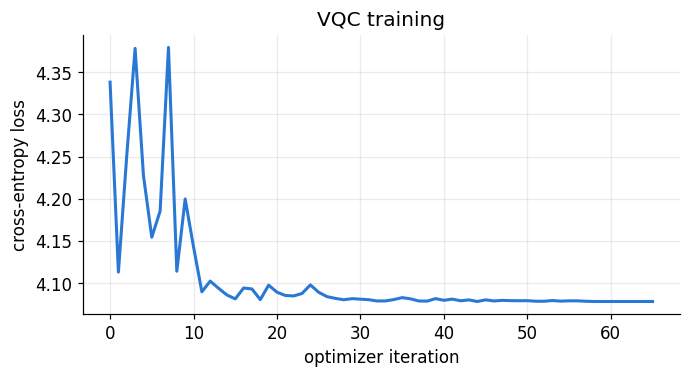

model,test accuracy
"VQC (ZZ map + RealAmplitudes, COBYLA)",0.20
quantum-kernel SVM (Part 4),0.90
tuned RBF SVM (Part 4),0.90


In [ ]:
loss_history = []
algorithm_globals.random_seed = 502
vqc = VQC(feature_map=fmap, ansatz=ansatz, optimizer=COBYLA(maxiter=150),
          sampler=StatevectorSampler(seed=SEED),        # 1024 shots per circuit by default
          callback=lambda weights, loss: loss_history.append(loss))
t0 = time.time()
vqc.fit(x_train, y_train)
print(f"training took {time.time() - t0:.0f} s and {len(loss_history)} loss evaluations")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(loss_history, color=BLUE, lw=2)
ax.set_xlabel("optimizer iteration"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC training")
plt.show()

acc_vqc_train, acc_vqc_test = vqc.score(x_train, y_train), vqc.score(x_test, y_test)
display(pd.DataFrame({"model": ["VQC (ZZ map + RealAmplitudes, COBYLA)", "quantum-kernel SVM (Part 4)", "tuned RBF SVM (Part 4)"],
                      "test accuracy": [acc_vqc_test, acc_q, acc_rbf]})
        .style.format({"test accuracy": "{:.2f}"}).hide(axis="index"))